# Simulated Annealing Callback Development

The python implementation of simulated annealing does not have a default
delta value to determine when to stop simulated annealing because it's
"good enough". We need to write in our own callback function to determine
"good enough", or we can specify how many iterations to run regardless.

This notebook allows for more rapid iteration of the simulated annealing
code in stare_pet, without having to run the whole pipeline to get to
the SA part first.

I saved out a list of argument lists while debugging stare_pet, so
we can just load that and run the whole multiprocessing on it. Or we
can pull one list of arguments from it and run SA on only one region.


In [24]:
%load_ext autoreload
%autoreload 2
import pickle
import logging
from minimize_cost import worker, run_in_mp_queue


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:

logging.basicConfig()
logger = logging.getLogger('SA_DEV')
logger.setLevel(logging.DEBUG)


In [16]:
sa_args_list = pickle.load(open(
    "/mnt/cache/stare_pet_20241230/NHFDG291/debug/sa_args_list.pickle", "rb"
))


In [17]:
# The worker gets sa_args_list[5], which is a tuple with 12 values:
#  0. i = 5
#  1. sa_bounds       = 24-len list
#                       [0.10, 0.18, 0.08, 0.14, 0.07, 0.13, ...]
#  2. src_tac         = TimeActivityCurve 21-len
#  3. hires_tac       = TimeActivityCurve 551-len
#  4. region_weights  = (7, )-shaped ndarray, weights-by-region
#  5. w               = (21, )-shaped ndarray, weights-by-time
#  6. target_tacs     = pd.DataFrame(21, 7), time x region
#  7. ki_peaks        = 8-len list, all 0.03 to 0.05
#  8. max_iter        = 1000
#  9. init_temp       = 5230
# 10. no_local_search = False
# 11. x0              = (24, )-shaped ndarray, initial values for
#                       [k1 for each of 8 regions,
#                        k2 for each of 8 regions,
#                        k3 for each of 8 regions]

# The worker only calculates costs once, with the final parameters.
# But solvestttm is called 66,348 additional times.
# The callback is executed 19 times.


In [28]:
# Run SA on only one region, no multiprocessing
result_dict = worker(sa_args_list[5])

# Took 2:41 naked,
# took 2:56 writing 50k stttm results to text file,
# took 2:44 writing four separate text files.


    Starting worker for region 5 at 12/31 10:34


/home/mike/.virtualenvs/stare/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


    Finished worker for region 5 at 12/31 10:36 after 0:02:44.940219.


In [ ]:
# Run SA on two regions, with multiprocessing
annealer_results = run_in_mp_queue(
    worker, sa_args_list[:2], 8, logger
)


In [20]:
# I manually had the solve_stttm function write every calculation to a file.
import pandas as pd

solve_costs = pd.read_csv("/home/mike/Desktop/stttm_costs.csv")


<Axes: ylabel='cost'>

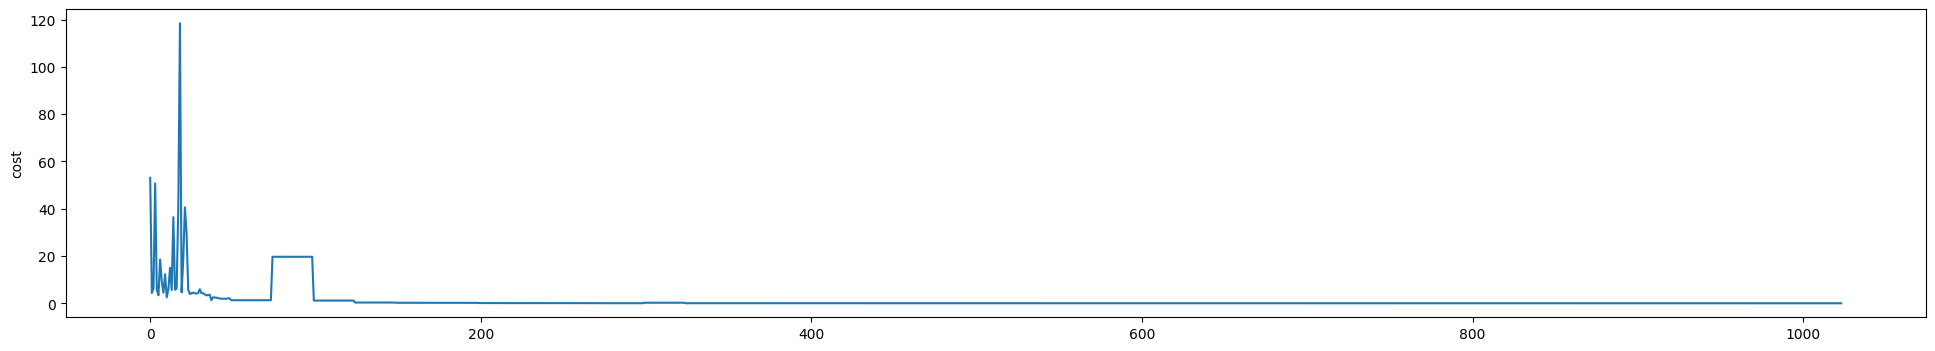

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(24, 4))
sns.lineplot(solve_costs.iloc[:1024], x=list(range(1024)), y="cost", ax=ax)



In [31]:
print([f"{c:0.8f}" for c in sorted(solve_costs['cost'])[:10]])

['0.00777000', '0.00777000', '0.00777000', '0.00777000', '0.00777000', '0.00777000', '0.00777000', '0.00777000', '0.00777000', '0.00777000']
